<a href="https://colab.research.google.com/github/Luoxiaowanzi/Class/blob/main/5150_Project_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

df = pd.read_csv("financial_data_win_project3.csv")

df.head()

,gvkey,firm_name,ticker,fyear,fiscal_year_end_month,fiscal_year_end,fiscal_year_end_prev,fiscal_year_end_next,earn_annc_date,earn_annc_date_prev,...,inventory_turnover,receivables_turnover,debt_equity,interest_coverage,capex_sales,ni_growth,ni_growth_next,rd_sales,sga_sales,fcf_ni
0,1045,AMERICAN AIRLINES GROUP INC,AMR,1995,12,1995-12-31,1994-12-31,1996-12-31,1996-01-18,1995-01-18,...,NaN,NaN,1.989785,2.263158,0.054879,NaN,6.083832,0.0,0.0,7.526946
1,1045,AMERICAN AIRLINES GROUP INC,AMR,1996,12,1996-12-31,1995-12-31,1997-12-31,1997-01-20,1996-01-18,...,24.032733,14.006312,0.899083,3.737475,0.030812,6.083832,0.969488,0.0,0.0,2.134843
2,1045,AMERICAN AIRLINES GROUP INC,AMR,1997,12,1997-12-31,1996-12-31,1998-12-31,1998-01-22,1997-01-20,...,24.271080,13.495640,0.711229,4.827068,0.074852,0.969488,1.334010,0.0,0.0,1.553299
3,1045,AMERICAN AIRLINES GROUP INC,AMR,1998,12,1998-12-31,1997-12-31,1999-12-31,1999-01-20,1998-01-22,...,25.292208,13.185719,0.657211,6.284946,0.138558,1.334010,0.749619,0.0,0.0,0.406393
4,1045,AMERICAN AIRLINES GROUP INC,AMR,1999,12,1999-12-31,1998-12-31,2000-12-31,2000-01-19,1999-01-20,...,23.745399,13.246171,0.907991,2.941476,0.199605,0.749619,0.825381,0.0,0.0,-1.294416


In [ ]:
# Outcome variable: next year's ROA
outcome = "roa_next"

# Predictor variables: information available in the current year
predictors = ["roa", "operating_margin", "current_ratio", "debt_equity"]

# Focal company: Coca-Cola
company_ticker = "KO"

# Training data ends in 2020
cutoff = 2020

# Keep only the variables we need and remove missing values
columns_needed = ["firm_name", "ticker", "fyear", outcome] + predictors
model_df = df[columns_needed].dropna().copy()

model_df.head()

,firm_name,ticker,fyear,roa_next,roa,operating_margin,current_ratio,debt_equity
1,AMERICAN AIRLINES GROUP INC,AMR,1996,0.048056,0.051953,0.105053,0.803090,0.899083
2,AMERICAN AIRLINES GROUP INC,AMR,1997,0.062826,0.048056,0.103716,0.902795,0.711229
3,AMERICAN AIRLINES GROUP INC,AMR,1998,0.044164,0.062826,0.121739,0.864515,0.657211
4,AMERICAN AIRLINES GROUP INC,AMR,1999,0.033355,0.044164,0.065200,0.754434,0.907991
5,AMERICAN AIRLINES GROUP INC,AMR,2000,-0.067219,0.033355,0.070091,0.740916,0.873746


In [ ]:
ko_check = model_df[model_df["ticker"] == company_ticker]

print(ko_check[["firm_name", "ticker", "fyear"]].head())
print("Number of usable Coca-Cola observations:", len(ko_check))
print("Years:", ko_check["fyear"].min(), "to", ko_check["fyear"].max())

         firm_name ticker  fyear
1971  COCA-COLA CO     KO   1996
1972  COCA-COLA CO     KO   1997
1973  COCA-COLA CO     KO   1998
1974  COCA-COLA CO     KO   1999
1975  COCA-COLA CO     KO   2000
Number of usable Coca-Cola observations: 29
Years: 1996 to 2024


In [ ]:
# General model: all companies, years through 2020
general_train = model_df[model_df["fyear"] <= cutoff].copy()

# Coca-Cola data
ko_df = model_df[model_df["ticker"] == company_ticker].copy()

# Firm-specific model: Coca-Cola only, years through 2020
ko_train = ko_df[ko_df["fyear"] <= cutoff].copy()

# Test data: Coca-Cola after 2020
ko_test = ko_df[ko_df["fyear"] > cutoff].copy()

print("General model training observations:", len(general_train))
print("Coca-Cola training observations:", len(ko_train))
print("Coca-Cola test observations:", len(ko_test))

General model training observations: 8035
Coca-Cola training observations: 25
Coca-Cola test observations: 4


In [ ]:
formula = "roa_next ~ roa + operating_margin + current_ratio + debt_equity"

# General market-wide model
general_model = smf.ols(formula, data=general_train).fit()

# Coca-Cola firm-specific model
ko_model = smf.ols(formula, data=ko_train).fit()

print("GENERAL MODEL RESULTS")
print(general_model.summary())

print("\nCOCA-COLA MODEL RESULTS")
print(ko_model.summary())

GENERAL MODEL RESULTS
                            OLS Regression Results                            
Dep. Variable:               roa_next   R-squared:                       0.207
Model:                            OLS   Adj. R-squared:                  0.207
Method:                 Least Squares   F-statistic:                     525.5
Date:                Sun, 15 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:42:41   Log-Likelihood:                 4226.3
No. Observations:                8035   AIC:                            -8443.
Df Residuals:                    8030   BIC:                            -8408.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept         

In [ ]:
# Compare regression coefficients and statistical significance
comparison = pd.DataFrame({
    "General Coefficient": general_model.params,
    "General P-value": general_model.pvalues,
    "Coca-Cola Coefficient": ko_model.params,
    "Coca-Cola P-value": ko_model.pvalues
})

comparison.round(4)

In [ ]:
ko_df["general_prediction"] = general_model.predict(ko_df)
ko_df["firm_prediction"] = ko_model.predict(ko_df)

ko_df[["fyear", "roa_next", "general_prediction", "firm_prediction"]]

,fyear,roa_next,general_prediction,firm_prediction
1971,1996,0.255492,0.167532,0.148514
1972,1997,0.208560,0.183782,0.185766
1973,1998,0.126978,0.157383,0.173154
1974,1999,0.100680,0.109456,0.137284
1975,2000,0.190506,0.095535,0.138766
1976,2001,0.136057,0.148558,0.182981
1977,2002,0.177421,0.117975,0.167752
1978,2003,0.177273,0.140652,0.173942
1979,2004,0.155521,0.141314,0.177207
1980,2005,0.172631,0.127784,0.165840


In [ ]:
# Re-create train and test data after predictions were added
ko_train = ko_df[ko_df["fyear"] <= cutoff].copy()
ko_test = ko_df[ko_df["fyear"] > cutoff].copy()

In [ ]:
def calculate_metrics(data, actual_column, prediction_column):
    errors = data[actual_column] - data[prediction_column]

    rmse = np.sqrt(np.mean(errors ** 2))
    mae = np.mean(np.abs(errors))

    return rmse, mae

results = []

for period_name, data in [
    ("In-sample (through 2020)", ko_train),
    ("Out-of-sample (2021–2024)", ko_test)
]:
    for model_name, prediction_column in [
        ("General model", "general_prediction"),
        ("Coca-Cola model", "firm_prediction")
    ]:
        rmse, mae = calculate_metrics(data, "roa_next", prediction_column)

        results.append({
            "Period": period_name,
            "Model": model_name,
            "RMSE": rmse,
            "MAE": mae
        })

metrics_table = pd.DataFrame(results)

# ROA is a decimal, so multiply by 100 to display percentage points
metrics_table["RMSE (%)"] = metrics_table["RMSE"] * 100
metrics_table["MAE (%)"] = metrics_table["MAE"] * 100

metrics_table[["Period", "Model", "RMSE (%)", "MAE (%)"]].round(2)

,Period,Model,RMSE (%),MAE (%)
0,In-sample (through 2020),General model,4.63,3.56
1,In-sample (through 2020),Coca-Cola model,3.81,2.84
2,Out-of-sample (2021–2024),General model,1.61,1.25
3,Out-of-sample (2021–2024),Coca-Cola model,1.14,0.93


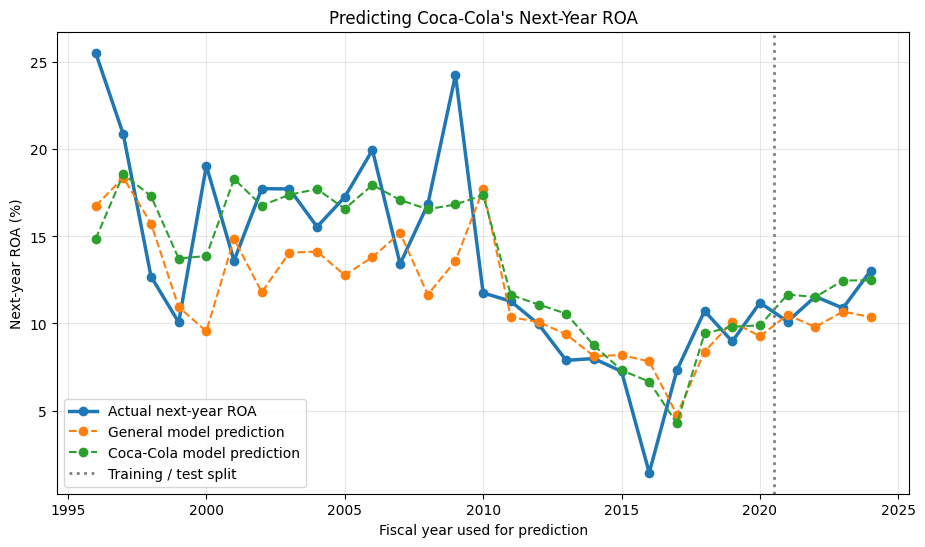

In [ ]:
plt.figure(figsize=(11, 6))

plt.plot(ko_df["fyear"], ko_df["roa_next"] * 100,
         marker="o", linewidth=2.5, label="Actual next-year ROA")

plt.plot(ko_df["fyear"], ko_df["general_prediction"] * 100,
         marker="o", linestyle="--", label="General model prediction")

plt.plot(ko_df["fyear"], ko_df["firm_prediction"] * 100,
         marker="o", linestyle="--", label="Coca-Cola model prediction")

plt.axvline(x=2020.5, color="gray", linestyle=":", linewidth=2,
            label="Training / test split")

plt.title("Predicting Coca-Cola's Next-Year ROA")
plt.xlabel("Fiscal year used for prediction")
plt.ylabel("Next-year ROA (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

This analysis predicted Coca-Cola’s next-year ROA and compared a general market-wide model with a Coca-Cola-specific model.

The Coca-Cola-specific model performed better in the 2021–2024 test period, with lower RMSE and MAE. This suggests that Coca-Cola’s own historical data is more useful for predicting its future ROA.

One limitation is that the test period only has four years of data.